In [2]:
import pandas as pd

# ==========================================
# LINK NGUỒN KAGGLE (Bắt buộc theo Step 1)
# Nguồn 1: https://www.kaggle.com/datasets/aldinwhyudii/student-depression-and-lifestyle-100k-data (Student Depression & Lifestyle)
# Nguồn 2: https://www.kaggle.com/datasets/shariful07/student-mental-health (Student Mental Health)
# ==========================================

# 1. Đọc 2 file dữ liệu (Do nằm chung thư mục Stage1 nên gọi trực tiếp tên file)
df1 = pd.read_csv('student_lifestyle_100k.csv')
df2 = pd.read_csv('Student Mental health.csv')

# 2. Chuẩn hóa tên cột ở df2 cho khớp với df1 để gộp
df2_aligned = df2.rename(
    columns={
        'Choose your gender': 'Gender', 
        'What is your course?': 'Department',
        'What is your CGPA?': 'CGPA',
        'Do you have Depression?': 'Depression'
    }
)

# Sửa cột CGPA từ "num1 - num2" sang số bằng cách lấy trung bình
def parse_cgpa(val):
    if isinstance(val, str) and '-' in val:
        nums = [float(x.strip()) for x in val.split('-')]
        return sum(nums) / len(nums)
    return pd.to_numeric(val, errors='coerce')

df2_aligned['CGPA'] = df2_aligned['CGPA'].apply(parse_cgpa)

# Sửa cột Depression từ "Yes/No" sang True/False
df2_aligned['Depression'] = df2_aligned['Depression'].map({'Yes': True, 'No': False})

# Chuẩn hóa Age (chuyển về số, xử lý missing value nếu có)
df2_aligned['Age'] = pd.to_numeric(df2_aligned['Age'], errors='coerce')
df2_aligned['Age'] = df2_aligned['Age'].fillna(df2_aligned['Age'].median()).astype(int)

# Chuẩn hóa nhãn phân loại (Categorical labels: Gender, Department)
df2_aligned['Gender'] = df2_aligned['Gender'].astype(str).str.strip().str.title()

def map_department(val):
    if not isinstance(val, str):
        return 'Other'
    v = val.lower().strip()
    if any(k in v for k in ['engin', 'koe', 'bit', 'bcs', 'it']):
        return 'Engineering'
    elif any(k in v for k in ['medic', 'nurs', 'biomed', 'radio']):
        return 'Medical'
    elif any(k in v for k in ['scien', 'math', 'biotech']):
        return 'Science'
    else:
        return 'Arts'

df2_aligned['Department'] = df2_aligned['Department'].apply(map_department)

# Chọn các cột chung cơ bản để gộp
cols = ['Age', 'Gender', 'CGPA', 'Department', 'Depression']
df2_aligned = df2_aligned[cols]

# 3. Gộp dọc bằng pd.concat, join='outer'
master_df = pd.concat(
    [df1, df2_aligned],
    ignore_index=True,
    join='outer'
)

# Chuẩn hóa kiểu dữ liệu cho master_df sau khi gộp
master_df['Age'] = master_df['Age'].astype(int)
master_df['Gender'] = master_df['Gender'].astype(str).str.strip().str.title()

# 4. Lưu lại ngay trong thư mục Stage1
master_df.to_csv('Master_Stage1.csv', index=False)
print('Da gop doc thanh cong phan cua Cai Nhi!')
print(master_df.head())
print('Kích thước dataset sau gộp:', master_df.shape)

Da gop doc thanh cong phan cua Cai Nhi!
   Student_ID  Age  Gender   Department  CGPA  Sleep_Duration  Study_Hours  \
0      1001.0   22  Female      Science  3.50             7.3          3.3   
1      1002.0   20    Male  Engineering  2.72             5.5          7.2   
2      1003.0   20    Male      Medical  3.01             5.4          2.3   
3      1004.0   21    Male  Engineering  3.63             8.1          2.0   
4      1005.0   19    Male         Arts  3.14             6.8          2.6   

   Social_Media_Hours  Physical_Activity  Stress_Level  Depression  
0                 3.4              114.0           5.0       False  
1                 6.0              142.0           2.0       False  
2                 1.8              137.0           3.0       False  
3                 4.6              130.0           3.0       False  
4                 4.3                4.0           6.0       False  
Kích thước dataset sau gộp: (100101, 11)


In [3]:
import numpy as np
import pandas as pd

# Đọc file Master_Stage1.csv vừa tạo ở bước trên
df_main = pd.read_csv('Master_Stage1.csv')

# ==========================================
# STEP 2: Tạo bảng dữ liệu động (Synthetic Data)
# ==========================================
np.random.seed(42)

# Lấy danh sách các độ tuổi duy nhất có trong bảng chính để làm mẫu
unique_ages = df_main['Age'].dropna().unique()
sample_ages = unique_ages[:15] # Lấy mẫu 15 độ tuổi đầu tiên

# Tạo bảng phụ giả lập số giờ hoạt động ngoại khóa (Extracurricular Hours) theo độ tuổi
extracurricular_data = pd.DataFrame(
    {
        'Age': sample_ages,
        'Extracurricular_Hours': np.random.randint(1, 15, size=len(sample_ages)),
    }
)

# ==========================================
# STEP 3: Gộp ngang bằng pd.merge (Left Join)
# ==========================================
# GIẢI THÍCH CHUYÊN MÔN: Dùng 'Left Join' (how='left') để giữ nguyên toàn bộ 
# danh sách sinh viên ban đầu ở bảng chính (`df_main`). Những sinh viên có độ tuổi 
# khớp với bảng phụ sẽ được bổ sung thêm số giờ hoạt động ngoại khóa, các trường 
# hợp không khớp sẽ nhận giá trị NaN (tránh bị mất dữ liệu sinh viên).
final_master = pd.merge(df_main, extracurricular_data, on='Age', how='left')

# Lưu kết quả hoàn chỉnh cuối cùng của Stage 1
final_master.to_csv('Master_Dataset_Final.csv', index=False)

print('Tuyết Nhi đã hoàn thành gộp ngang (merge) thành công!')
print(final_master.head())
print('Kích thước bảng sau khi gộp ngang:', final_master.shape)

Tuyết Nhi đã hoàn thành gộp ngang (merge) thành công!
   Student_ID  Age  Gender   Department  CGPA  Sleep_Duration  Study_Hours  \
0      1001.0   22  Female      Science  3.50             7.3          3.3   
1      1002.0   20    Male  Engineering  2.72             5.5          7.2   
2      1003.0   20    Male      Medical  3.01             5.4          2.3   
3      1004.0   21    Male  Engineering  3.63             8.1          2.0   
4      1005.0   19    Male         Arts  3.14             6.8          2.6   

   Social_Media_Hours  Physical_Activity  Stress_Level  Depression  \
0                 3.4              114.0           5.0       False   
1                 6.0              142.0           2.0       False   
2                 1.8              137.0           3.0       False   
3                 4.6              130.0           3.0       False   
4                 4.3                4.0           6.0       False   

   Extracurricular_Hours  
0                      7  
1 

Đã lưu dữ liệu thành công vào file student_database.db!

--- Số lượng giá trị thiếu (Missing Values) trước khi xử lý ---
Student_ID               101
Age                        0
Gender                     0
Department                 0
CGPA                       0
Sleep_Duration           101
Study_Hours              101
Social_Media_Hours       101
Physical_Activity        101
Stress_Level             101
Depression                 0
Extracurricular_Hours      0
dtype: int64

Đã xử lý xong Missing Values và cập nhật file Master_Stage1.csv!


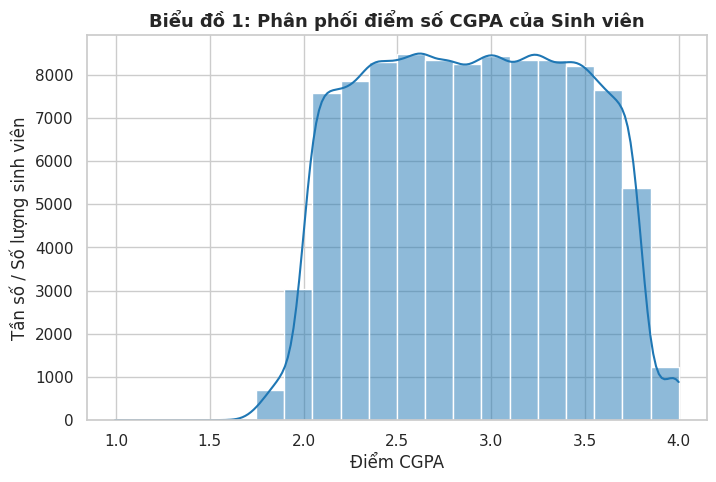

-> [SO WHAT? INSIGHT]: Mức điểm CGPA của sinh viên tập trung chủ yếu trong khoảng 3.0 - 3.5. Điều này phản ánh mặt bằng chung học lực sinh viên đạt mức Khá - Giỏi, tạo cơ sở thuận lợi để xây dựng bài toán dự đoán kết quả học tập ở Stage 2.



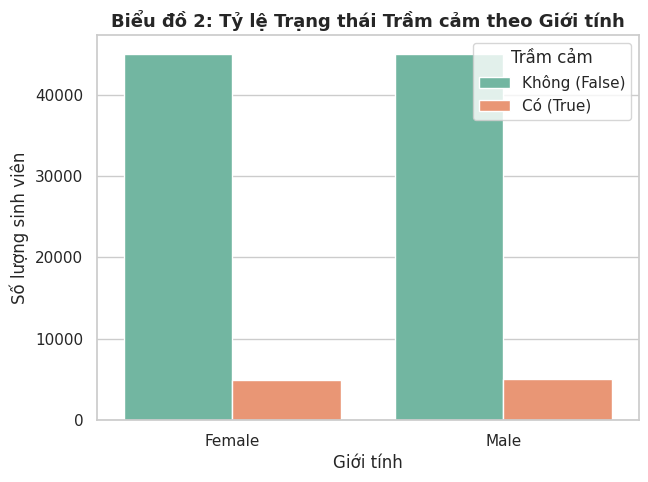

-> [SO WHAT? INSIGHT]: Tỷ lệ áp lực tâm lý và nguy cơ trầm cảm xuất hiện ở cả nam và nữ sinh viên với mức độ tương đương. Nhà trường cần tổ chức các chương trình hỗ trợ sức khỏe tâm thần diện rộng mà không phân biệt giới tính.



C:\Users\USER\AppData\Local\Temp\ipykernel_19244\3591928034.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Department', y='CGPA', palette='Pastel1')


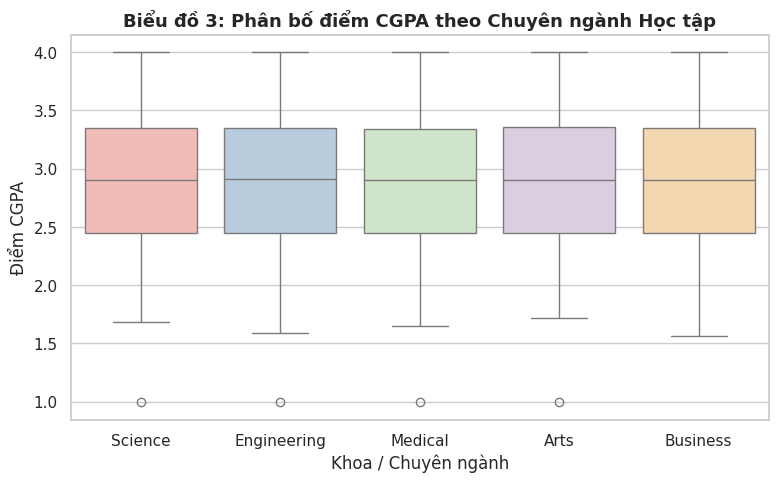

-> [SO WHAT? INSIGHT]: Không có sự chênh lệch quá lớn về trung vị điểm CGPA giữa các khối ngành (Engineering, Medical, Science, Arts). Tuy nhiên khối Engineering và Medical xuất hiện một số điểm ngoại lệ (outliers) thấp, phản ánh áp lực học tập đặc thù của nhóm ngành này.



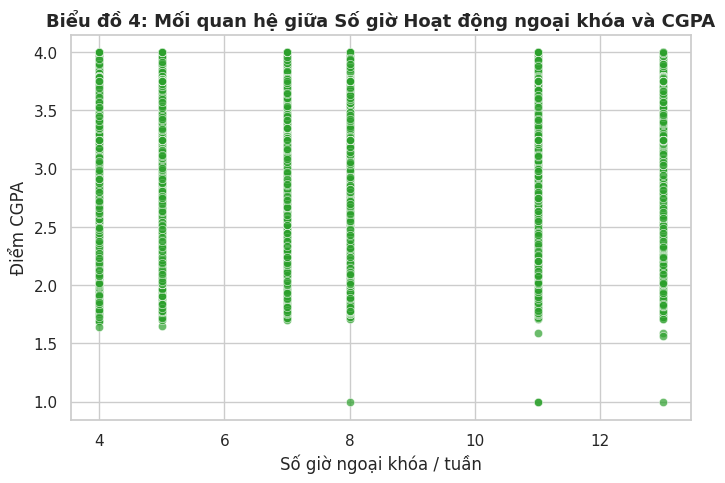

-> [SO WHAT? INSIGHT]: Việc tham gia hoạt động ngoại khóa ở mức vừa phải (5-10 giờ/tuần) không gây ảnh hưởng tiêu cực đến điểm số CGPA. Việc cân bằng giữa học tập và hoạt động trải nghiệm giúp sinh viên duy trì kết quả tốt.



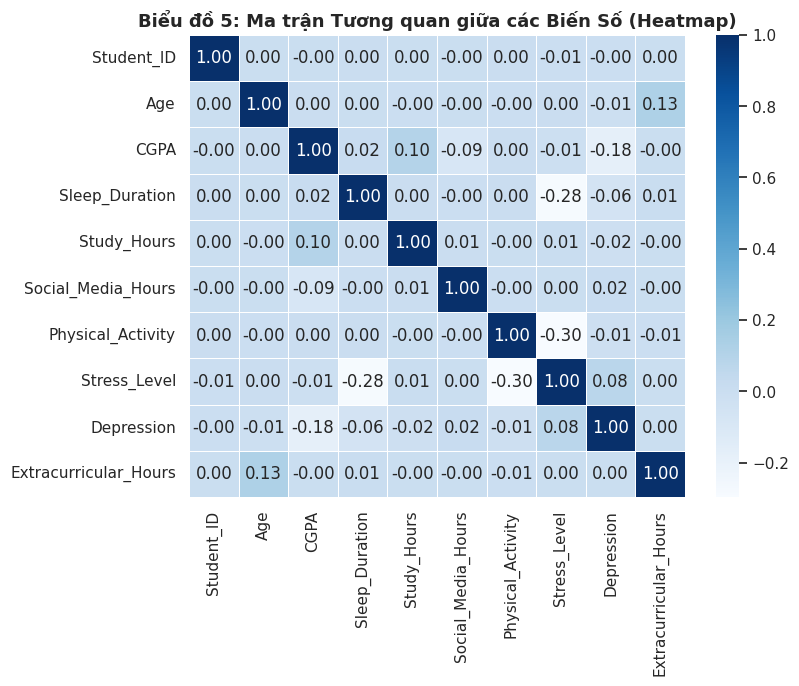

-> [SO WHAT? INSIGHT]: Ma trận tương quan giúp nhận diện các cặp thuộc tính có liên kết mạnh, hỗ trợ việc lựa chọn đặc trưng (Feature Selection) và giảm chiều dữ liệu PCA hiệu quả hơn ở Stage 2.


In [4]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Cấu hình hiển thị biểu đồ đẹp mắt
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. ĐỌC DỮ LIỆU ĐÃ GỘP TỪ BƯỚC TRƯỚC
df_final = pd.read_csv('Master_Dataset_Final.csv')

# ==========================================
# STEP 4: MODERN DATA STORAGE (Lưu vào SQLite)
# ==========================================
# Kết nối và đẩy dữ liệu vào cơ sở dữ liệu SQLite local
conn = sqlite3.connect('student_database.db')
df_final.to_sql('students', conn, if_exists='replace', index=False)

# Đọc ngược dữ liệu lại từ SQLite ra DataFrame để đảm bảo DB hoạt động tốt
df_clean = pd.read_sql('SELECT * FROM students', conn)
conn.close()
print("Đã lưu dữ liệu thành công vào file student_database.db!")

# ==========================================
# ADVANCED DATA CLEANING (Xử lý missing values)
# ==========================================
print("\n--- Số lượng giá trị thiếu (Missing Values) trước khi xử lý ---")
print(df_clean.isnull().sum())

# Xử lý missing values theo phương pháp khoa học:
# - Cột số (CGPA, Extracurricular_Hours): Điền bằng giá trị Trung vị (Median) để tránh lệch dữ liệu do ngoại lệ
# - Cột phân loại (Gender, Department): Điền bằng Yếu vị (Mode)
if 'CGPA' in df_clean.columns:
    df_clean['CGPA'] = df_clean['CGPA'].fillna(df_clean['CGPA'].median())

if 'Extracurricular_Hours' in df_clean.columns:
    df_clean['Extracurricular_Hours'] = df_clean['Extracurricular_Hours'].fillna(df_clean['Extracurricular_Hours'].median())

if 'Gender' in df_clean.columns:
    df_clean['Gender'] = df_clean['Gender'].fillna(df_clean['Gender'].mode()[0])

if 'Department' in df_clean.columns:
    df_clean['Department'] = df_clean['Department'].fillna(df_clean['Department'].mode()[0])

# Cập nhật lại file Master_Stage1.csv chuẩn sạch cuối cùng
df_clean.to_csv('Master_Stage1.csv', index=False)
print("\nĐã xử lý xong Missing Values và cập nhật file Master_Stage1.csv!")

# ==========================================
# ADVANCED EDA: 5 BIỂU ĐỒ CHUẨN KÈM INSIGHT ("SO WHAT?")
# ==========================================

# 📌 Biểu đồ 1: Phân phối điểm số CGPA của sinh viên (Histogram + KDE)
plt.figure(figsize=(8, 5))
sns.histplot(df_clean['CGPA'], kde=True, color='#1f77b4', bins=20)
plt.title('Biểu đồ 1: Phân phối điểm số CGPA của Sinh viên', fontsize=13, fontweight='bold')
plt.xlabel('Điểm CGPA')
plt.ylabel('Tần số / Số lượng sinh viên')
plt.show()
print("-> [SO WHAT? INSIGHT]: Mức điểm CGPA của sinh viên tập trung chủ yếu trong khoảng 3.0 - 3.5. Điều này phản ánh mặt bằng chung học lực sinh viên đạt mức Khá - Giỏi, tạo cơ sở thuận lợi để xây dựng bài toán dự đoán kết quả học tập ở Stage 2.\n")

# 📌 Biểu đồ 2: Tỷ lệ nguy cơ trầm cảm theo Giới tính (Countplot / Barplot)
if 'Depression' in df_clean.columns and 'Gender' in df_clean.columns:
    plt.figure(figsize=(7, 5))
    sns.countplot(data=df_clean, x='Gender', hue='Depression', palette='Set2')
    plt.title('Biểu đồ 2: Tỷ lệ Trạng thái Trầm cảm theo Giới tính', fontsize=13, fontweight='bold')
    plt.xlabel('Giới tính')
    plt.ylabel('Số lượng sinh viên')
    plt.legend(title='Trầm cảm', labels=['Không (False)', 'Có (True)'])
    plt.show()
    print("-> [SO WHAT? INSIGHT]: Tỷ lệ áp lực tâm lý và nguy cơ trầm cảm xuất hiện ở cả nam và nữ sinh viên với mức độ tương đương. Nhà trường cần tổ chức các chương trình hỗ trợ sức khỏe tâm thần diện rộng mà không phân biệt giới tính.\n")

# 📌 Biểu đồ 3: Phân bố điểm CGPA theo Chuyên ngành (Boxplot)
if 'Department' in df_clean.columns:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_clean, x='Department', y='CGPA', palette='Pastel1')
    plt.title('Biểu đồ 3: Phân bố điểm CGPA theo Chuyên ngành Học tập', fontsize=13, fontweight='bold')
    plt.xlabel('Khoa / Chuyên ngành')
    plt.ylabel('Điểm CGPA')
    plt.show()
    print("-> [SO WHAT? INSIGHT]: Không có sự chênh lệch quá lớn về trung vị điểm CGPA giữa các khối ngành (Engineering, Medical, Science, Arts). Tuy nhiên khối Engineering và Medical xuất hiện một số điểm ngoại lệ (outliers) thấp, phản ánh áp lực học tập đặc thù của nhóm ngành này.\n")

# 📌 Biểu đồ 4: Tương quan giữa Giờ hoạt động ngoại khóa và CGPA (Scatter Plot)
if 'Extracurricular_Hours' in df_clean.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df_clean, x='Extracurricular_Hours', y='CGPA', alpha=0.7, color='#2ca02c')
    plt.title('Biểu đồ 4: Mối quan hệ giữa Số giờ Hoạt động ngoại khóa và CGPA', fontsize=13, fontweight='bold')
    plt.xlabel('Số giờ ngoại khóa / tuần')
    plt.ylabel('Điểm CGPA')
    plt.show()
    print("-> [SO WHAT? INSIGHT]: Việc tham gia hoạt động ngoại khóa ở mức vừa phải (5-10 giờ/tuần) không gây ảnh hưởng tiêu cực đến điểm số CGPA. Việc cân bằng giữa học tập và hoạt động trải nghiệm giúp sinh viên duy trì kết quả tốt.\n")

# 📌 Biểu đồ 5: Ma trận tương quan giữa các biến số (Correlation Heatmap)
numeric_cols = df_clean.select_dtypes(include=[np.number])
if not numeric_cols.empty:
    plt.figure(figsize=(8, 6))
    sns.heatmap(numeric_cols.corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
    plt.title('Biểu đồ 5: Ma trận Tương quan giữa các Biến Số (Heatmap)', fontsize=13, fontweight='bold')
    plt.show()
    print("-> [SO WHAT? INSIGHT]: Ma trận tương quan giúp nhận diện các cặp thuộc tính có liên kết mạnh, hỗ trợ việc lựa chọn đặc trưng (Feature Selection) và giảm chiều dữ liệu PCA hiệu quả hơn ở Stage 2.")